# Compute margins

[Read results](read-results.ipynb) reads a saved state by name. This page adds boiling limits to one, on the pair of [Build a plate, an assembly or a rod](build-a-plate-or-rod.ipynb), at steady state and over a short coastdown. [Thresholds](../thresholds.rst) tabulates the limits, their correlations and their references.

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc("font", family="serif", size=15)

from stream.analysis.thresholds import (
    Bergles_Rohsenow_T_ONB,
    Sudo_Kaminaga_CHF,
    Whittle_Forgan_OFI,
    threshold_analysis,
    transient_threshold_analysis,
)
from stream.calculations import ChannelAndContacts, Fuel, Solid
from stream.calculations.channel import Direction
from stream.composition import symmetric_plate, symmetric_plate_steady_state, uniform_x_power_shape, x_boundaries
from stream.physical_models.heat_transfer_coefficient import spl_htc, wall_heat_transfer_coeff
from stream.physical_models.pressure_drop import friction_factor, pressure_diff, rectangular_laminar_correction
from stream.physical_models.thresholds import saturation_margin
from stream.pipe_geometry import EffectivePipe
from stream.substances import light_water
from stream.utilities import factor

## The pair, solved

The cell rebuilds the pair, solves it at 0.5 kg/s and saves the state; its aggregator binds the coastdown $\dot m(t) = \dot m_0 / (1 + t / 20\,\mathrm{s})$ for later. Every wrapper but `twall_limit` reads `static_pressure`, which a channel saves only when `p_abs` is bound.

In [2]:
length, width, cells = 0.7, 0.070, 10
clad_N, fuel_N, clad_w, meat_w = 2, 8, 0.0005, 0.0006
z = np.linspace(0.0, length, cells + 1)
meat = np.zeros((cells, fuel_N + 2 * clad_N), dtype=bool)
meat[:, clad_N:-clad_N] = True
fuel = Fuel(
    z_boundaries=z,
    x_boundaries=x_boundaries(clad_N, fuel_N, clad_w, meat_w),
    material=Solid.from_array(np.where(meat, Solid(3500, 750, 40), Solid(2700, 900, 167))),
    y_length=width,
    power_shape=uniform_x_power_shape(cells, fuel_N, clad_N, clad_w, meat_w, length),
    meat_indices=meat,
    name="Plate",
)
pipe = EffectivePipe.rectangular(length=length, edge1=width, edge2=0.0022, heated_edge=width)
aspect_ratio = pipe.depth / pipe.width
h_spl = spl_htc("regime_dependent", re_bounds=(2000.0, 5000.0), Lh=length, aspect_ratio=aspect_ratio)
f = friction_factor("regime_dependent", re_bounds=(2000.0, 5000.0), k_R=rectangular_laminar_correction(aspect_ratio))
channel = ChannelAndContacts(
    z_boundaries=z,
    fluid=light_water,
    pipe=pipe,
    h_wall_func=partial(wall_heat_transfer_coeff, h_spl=h_spl),
    pressure_func=partial(pressure_diff, f=f),
    name="Channel",
)
mdot0, p_abs, power, T_in = 0.5, 1.8e5, 25e3, 38.0
steady = symmetric_plate_steady_state(channel, fuel, mdot=mdot0, p_abs=p_abs, power=power, Tin=T_in)
funcs = {channel: {"mdot": lambda t: mdot0 / (1 + t / 20.0), "p_abs": p_abs, "Tin": T_in}, fuel: {"power": power}}
agr = symmetric_plate(channel, fuel, funcs=funcs).to_aggregator()
y = agr.load(steady)
state = agr.save(y)
print(f"channel power:  {state['Channel']['power'] / 1e3:.2f} kW")
print(f"peak heat flux: {state['Channel']['q, left'].max() / 1e3:.1f} kW/m²")

channel power:  25.00 kW
peak heat flux: 394.2 kW/m²


The channel carries the plate's 25 kW, and its flux peaks at about 394 kW/m².

## The thresholds on a state

`threshold_analysis(**funcs)` returns an analyser, `analyzer(state, agr, name)`, that looks the channel up by name, calls every function with the channel's saved state and its `fluid`, `pipe` and `dz` by keyword, and writes each result under its keyword into a deep copy. The functions come from `stream.analysis.thresholds`; the same name imported from `stream` is the raw correlation, which takes physical arguments and fails here with a `TypeError` on the keyword `state`. `Bergles_Rohsenow_T_ONB` and `Saha_Zuber_OSV` require a `direction`, the wall they read, bound with `partial`.

In [3]:
onb = partial(Bergles_Rohsenow_T_ONB, direction=Direction.left)
analysed = threshold_analysis(ONB=onb, CHF=Sudo_Kaminaga_CHF, OFI=Whittle_Forgan_OFI)(state, agr, "Channel")
new = sorted(set(analysed["Channel"]) - set(state["Channel"]))
print(f"new keys:            {new}")
print(f"input state changed: {'CHF' in state['Channel']}")

new keys:            ['CHF', 'OFI', 'ONB']
input state changed: False


Three keys arrived in the copy; the saved state is untouched.

## Levels and margins

Most wrappers return a level; the ONB wrapper returns the margin itself.

| Wrapper | Returns | Margin |
|---|---|---|
| `Sudo_Kaminaga_CHF`, `Mirshak_CHF`, `Fabrega_CHF` | critical flux per cell [W/m²] | level minus the wall flux `q, left` |
| `Saha_Zuber_OSV` | void-onset flux per cell [W/m²] | level minus the wall flux `q, left` |
| `Whittle_Forgan_OFI` | flow-instability power [W] | level minus `power` |
| `boiling_power` | saturation power per cell [W] | level minus `power` |
| `twall_limit` | hotter wall temperature per cell [°C] | to a design limit |
| `Bergles_Rohsenow_T_ONB` | $T_{wall} - T_{ONB}$ per cell [K] | the key itself |

Each correlation holds over the range its docstring states: `Fabrega_CHF` for flows below 0.5 m/s, `Mirshak_CHF` above 1.5 m/s. A level margin is positive while the channel is short of the threshold; the ONB key is negative below the onset of nucleate boiling and positive past it, so the worst cell has the smallest level margin and the largest ONB key. On a plain `Channel`, which saves no wall flux, `twall_limit` returns minus infinity without a warning.

![A heat-flux level with its margin to the wall flux, and the temperatures that set the ONB key.](../_static/howto/levels-and-margins.svg)

*In (a) a safety factor scales the level, the margin follows; in (b) onb_factor=0.8 lowers the ONB temperature, and the ONB key rises.*

In [4]:
c = analysed["Channel"]
print(f"CHF margin, worst cell: {(c['CHF'] - c['q, left']).min() / 1e6:.3f} MW/m²")
print(f"OFI margin:             {(c['OFI'] - c['power']) / 1e3:.1f} kW")
print(f"ONB key, worst cell:    {c['ONB'].max():.2f} K")

CHF margin, worst cell: 1.280 MW/m²
OFI margin:             117.3 kW
ONB key, worst cell:    -55.14 K


The pair is far from the three limits computed here: about 1.28 MW/m² below the critical flux, about 117 kW below the flow excursion, and its wall about 55 K below boiling onset.

## A safety factor

`factor(f, by=k)` from `stream.utilities` multiplies what `f` returns by `k`: on a level wrapper it scales the level. On the ONB key it would scale the margin, so that wrapper takes `onb_factor`, which multiplies the superheat in $T_{ONB} = T_{sat} + \Delta T_{ONB}$. `inhomogeneity_factor`, on the ONB, OSV and wall-temperature wrappers, multiplies the local flux, a hot-spot factor.

In [5]:
scaled = threshold_analysis(
    CHF_80=factor(Sudo_Kaminaga_CHF, by=0.8),
    ONB_80=partial(Bergles_Rohsenow_T_ONB, direction=Direction.left, onb_factor=0.8),
)(state, agr, "Channel")["Channel"]
print(f"CHF margin at 0.8 CHF:        {(scaled['CHF_80'] - c['q, left']).min() / 1e6:.4f} MW/m²")
print(f"ONB key at 0.8 of superheat:  {scaled['ONB_80'].max():.2f} K")

CHF margin at 0.8 CHF:        0.9453 MW/m²
ONB key at 0.8 of superheat:  -53.85 K


Both factors move the threshold toward the channel: the CHF margin falls from about 1.28 to about 0.945 MW/m², and the ONB key rises from about -55.1 to about -53.9 K.

## Over a transient

`transient_threshold_analysis(**funcs)` applies the same analyser at every time of a history, the `dict` that `agr.save(sol)` returns. Any function with that keyword signature can be a key: here `saturation_margin(T_bulk, T_sat)` from `stream.physical_models.thresholds` at the static pressure, the margin a `ChannelAndContacts` built with `stop_at_saturation=True` watches as an event. The cell runs 30 s of the coastdown.

saturation margin at 0 s and 30 s: 62.9 K, 49.6 K
ONB key at 0 s and 30 s:           -55.1 K, -29.7 K


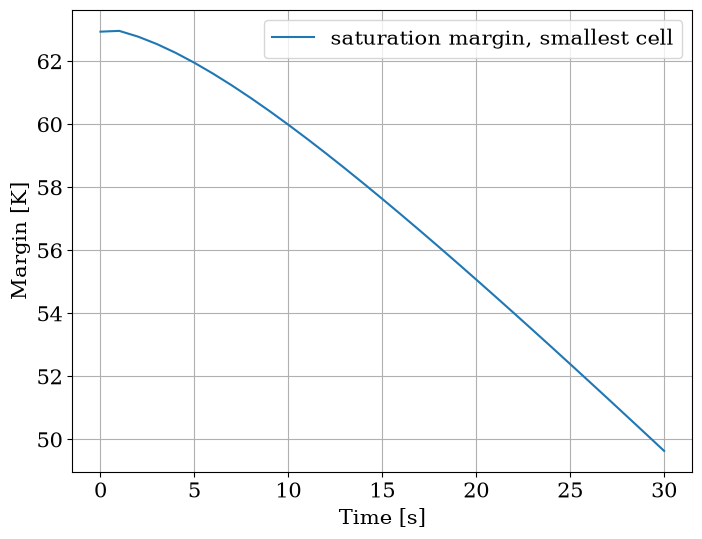

In [6]:
def subcooling(*, state, fluid, **_):
    return saturation_margin(state["T_cool"], fluid.sat_temperature(state["static_pressure"]))


sol = agr.solve(y, np.linspace(0.0, 30.0, 31))
history = transient_threshold_analysis(SAT=subcooling, ONB=onb)(agr.save(sol), agr, "Channel")
sat = np.array([history[t]["Channel"]["SAT"].min() for t in sol.time])
onb_t = np.array([history[t]["Channel"]["ONB"].max() for t in sol.time])
print(f"saturation margin at 0 s and 30 s: {sat[0]:.1f} K, {sat[-1]:.1f} K")
print(f"ONB key at 0 s and 30 s:           {onb_t[0]:.1f} K, {onb_t[-1]:.1f} K")
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(sol.time, sat, label="saturation margin, smallest cell")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Margin [K]")
ax.grid()
ax.legend()
plt.show()

As the flow falls the smallest saturation margin drops from about 63 K to about 50 K; the wall moves faster, its ONB key rising from about -55 K to about -30 K.

[Both Pumps Trip](../LOFABothPumpsTrip.ipynb#The-hot-plate) follows the saturation margin of the hottest plate through an hour. [How many cells along the plate](../LOFAVariations.ipynb#How-many-cells-along-the-plate) measures how that margin moves with the axial mesh, the next question to ask of a margin before quoting it.